# bezier-rfm summary: from Lift parity to the training plan

**Who this is for:** a reader who wants the results of H14–H25 in one place, before the training dataset is built.

**What this notebook does:** it loads stored results only. It runs no simulation and no fit, so it runs from top to bottom in seconds. Numbers without a small result file come from `docs/hypotheses.md`, with their H-numbers.

**Outline**

- **Part 1 (H14–H24).** Lift: the absolute-action interface and fit parity.
- **Part 2 (H25.0–H25.1b).** Tool Hang: open-loop replay is fragile.
- **Part 3 (H25.3–H25.5).** Tool Hang: success rises with segment density.
- **Part 4 (H25.6).** The speed rule: the chosen knot placement.
- **Part 5.** The training plan (details in `docs/plan.md`).

In [1]:
import json
from collections import Counter
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial.transform import Rotation
from scipy.stats import binomtest

from bezier_rfm.fitting.density import speed_weight

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
LIFT = ROOT / "data/robomimic/datasets/lift/ph"
TOOL_HANG = ROOT / "data/robomimic/datasets/tool_hang/ph"
SCREENING = ROOT / "docs/tool_hang/screening"
CONTROL_DT = 0.05
# The 5 demos that failed most at 3 segments/s (H25.5).
WORST = ["demo_189", "demo_82", "demo_66", "demo_16", "demo_137"]


def load_runs(name):
    # One screening file: runs of the nominal replay (seed 0) and 5 noisy replays per demo.
    return json.loads((SCREENING / f"{name}.json").read_text())["runs"]


def successes(runs, demos=None):
    # Screening success: the task succeeds within the actions or the 60 hold steps.
    return sum(r["success_with_hold"] for r in runs if demos is None or r["demo"] in demos)


def rotation_angle(rotvec_a, rotvec_b):
    # Geodesic angle between two sets of rotations given as rotation vectors.
    return (Rotation.from_rotvec(rotvec_a).inv() * Rotation.from_rotvec(rotvec_b)).magnitude()

---
# Part 1. Lift: the absolute-action interface and fit parity (H14–H24)

The policy generates commanded grip-site poses, so the data must contain them. RoboMimic stores delta actions. The Lift work converted them to absolute world-frame goals, then showed that each step of the chain keeps the task outcome.

| H | Step | Result |
| --- | --- | --- |
| H14 | The Python 3.12 stack runs Lift | `actions[t]` gives the smallest arm error at all 58 steps of demo_0. The controller frame is the grip site. |
| H15 | Delta → absolute conversion | All 200 demos within 7.5e-16 m and 7.1e-7 rad. 92 rotation-vector wraps near π. |
| H16 | Same next state, one step | 9540 of 9666 steps agree to about 2e-13 m. The other 126 are in contact, where the simulator is sensitive. |
| H17 | Absolute replay | Lifts the cube in 199 of 200 demos (demo_177 fails in every replay). |
| H20–H21 | q0-start reference | Action 0 = actual start pose. Same 199 of 200. This file is the fit target. |
| H22 | R³ × SO(3) decoder | C¹ in seconds at every knot (velocity match 4e-15). |
| H24 | Fits of all 200 demos | (K1, K2) = (3, 2), (5, 2), (6, 3): all 600 fits converge and lift the cube in the same 199 of 200 demos. |

The figure shows the K = (5, 2) fit of demo_0 against its commands.

In [2]:
with h5py.File(LIFT / "low_dim_abs_q0start.hdf5", "r") as f:
    lift_cmd = f["data/demo_0/actions"][:]
with h5py.File(LIFT / "bezier_k5_2.hdf5", "r") as f:
    lift_fit = f["data/demo_0/actions"][:]
    lift_diag = json.loads(f["data/demo_0/bezier"].attrs["diagnostics"])

lift_t = CONTROL_DT * np.arange(len(lift_cmd))
lift_pos_err = np.linalg.norm(lift_fit[:, :3] - lift_cmd[:, :3], axis=1)
lift_rot_err = rotation_angle(lift_cmd[:, 3:6], lift_fit[:, 3:6])
print(f"demo_0, K = (5, 2): position RMS {1e3 * np.sqrt(np.mean(lift_pos_err**2)):.1f} mm, max {1e3 * lift_pos_err.max():.1f} mm; "
      f"rotation RMS {np.degrees(np.sqrt(np.mean(lift_rot_err**2))):.2f} deg, max {np.degrees(lift_rot_err.max()):.2f} deg")
print(f"stored diagnostics: position RMS {1e3 * lift_diag['pos_rms_m']:.1f} mm, rotation RMS {np.degrees(lift_diag['rot_rms_rad']):.2f} deg")

demo_0, K = (5, 2): position RMS 4.7 mm, max 10.6 mm; rotation RMS 0.28 deg, max 1.68 deg
stored diagnostics: position RMS 4.7 mm, rotation RMS 0.28 deg


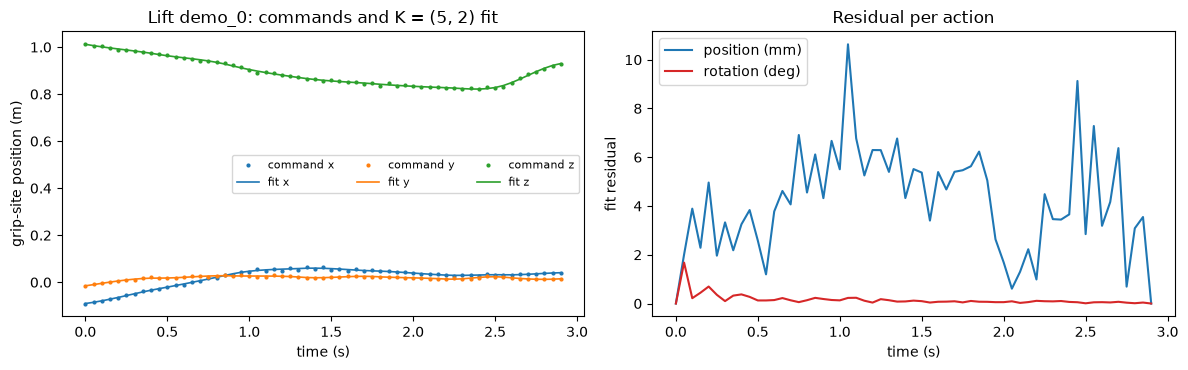

In [3]:
fig, (ax_p, ax_e) = plt.subplots(1, 2, figsize=(12, 3.8))
for i, (axis, color) in enumerate(zip("xyz", ["C0", "C1", "C2"])):
    ax_p.plot(lift_t, lift_cmd[:, i], ".", color=color, ms=4, label=f"command {axis}")
    ax_p.plot(lift_t, lift_fit[:, i], "-", color=color, lw=1.2, label=f"fit {axis}")
ax_p.set(xlabel="time (s)", ylabel="grip-site position (m)", title="Lift demo_0: commands and K = (5, 2) fit")
ax_p.legend(ncol=3, fontsize=8)
ax_e.plot(lift_t, 1e3 * lift_pos_err, color="C0", label="position (mm)")
ax_e.plot(lift_t, np.degrees(lift_rot_err), color="C3", label="rotation (deg)")
ax_e.set(xlabel="time (s)", ylabel="fit residual", title="Residual per action")
ax_e.legend()
fig.tight_layout()

**Reading.** Seven segments follow the commands of a full Lift demo: the position residual stays below 11 mm, and the rotation residual below 0.5° after the first steps. The rotation peak at the start comes from the jump in the first command of the 3D mouse (H20). On Lift, the fits keep the task outcome in every demo where the reference succeeds.

---
# Part 2. Tool Hang: open-loop replay is fragile (H25.0–H25.1b)

Tool Hang PH has 200 demos with 4 gripper events (9 demos have 6) and 776 rotation-vector wraps near π (H25.0). The conversion passes the H15 checks.

On Lift, open-loop replay of the commands reproduces the task. On Tool Hang it does not (H25.1: q0-start replay succeeds in 2 of 12 demos). So the screening protocol replays each demo 6 times: the nominal run, plus 5 runs with 0.2 mm / 0.2 mrad noise on the commands, all with 60 hold steps at the end.

In [4]:
screen = load_runs("screen_q0start")
nominal = [r for r in screen if r["seed"] == 0]
per_demo = Counter()
for r in screen:
    per_demo[r["demo"]] += r["success_with_hold"]
robust = sorted((d for d, k in per_demo.items() if k == 6), key=lambda d: int(d.split("_")[1]))
print(f"nominal replay: {sum(r['success_in_actions'] for r in nominal)} of 200 within the actions, "
      f"{sum(r['success_with_hold'] for r in nominal)} of 200 with hold steps")
print(f"demos that succeed in 6 of 6 runs: {len(robust)}")

nominal replay: 68 of 200 within the actions, 82 of 200 with hold steps
demos that succeed in 6 of 6 runs: 19


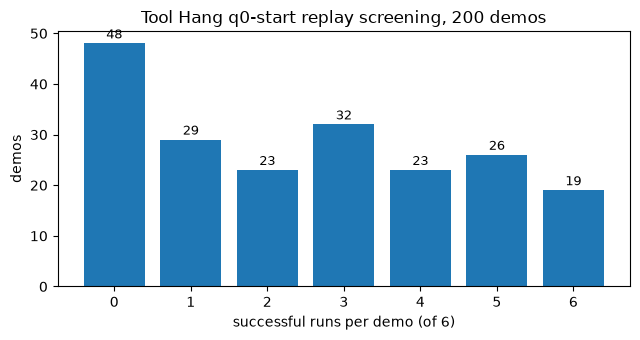

In [5]:
hist = Counter(per_demo.values())
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.bar(range(7), [hist[k] for k in range(7)], color="C0")
for k in range(7):
    ax.text(k, hist[k] + 1, str(hist[k]), ha="center", fontsize=9)
ax.set(xlabel="successful runs per demo (of 6)", ylabel="demos", title="Tool Hang q0-start replay screening, 200 demos")
fig.tight_layout()

**Reading.** Most demos succeed in some runs and fail in others. A 0.2 mm change of the commands often flips the outcome. So open-loop replay success is a weak test of a fit, and it does not test a policy. The fit tests below use only the 19 demos that succeed in all 6 runs, and compare each fit with the reference on the same runs.

---
# Part 3. Tool Hang: success rises with segment density (H25.3–H25.5)

Each fit uses K = density × demo duration segments. Two knot rules:

- **E (event):** knots at the gripper events, and segments spread uniformly within each phase.
- **U (uniform):** segments spread uniformly over the whole demo.

Panel (a): the 19 robust demos at 1.5 and 3 segments/s (114 runs per rule, H25.4). Panel (b): the 5 demos that failed most at 3 /s, also at 6 /s (30 runs, H25.5).

In [6]:
runs = {name: load_runs(name) for name in [
    "h25_4_reference", "h25_4_event_rho1.5", "h25_4_uniform_rho1.5", "h25_4_event_rho3", "h25_4_uniform_rho3",
    "h25_4_event_rho6", "h25_4_uniform_rho6", "h25_6_release_rho3", "h25_6_speed_rho3"]}
for name, rr in runs.items():
    print(f"{name:22s} {len(rr):3d} runs: {successes(rr):3d} succeed | 5 worst demos: {successes(rr, WORST):2d} of {sum(r['demo'] in WORST for r in rr)}")

h25_4_reference        114 runs: 114 succeed | 5 worst demos: 30 of 30
h25_4_event_rho1.5     114 runs:  38 succeed | 5 worst demos:  1 of 30
h25_4_uniform_rho1.5   114 runs:  47 succeed | 5 worst demos:  2 of 30
h25_4_event_rho3       114 runs:  81 succeed | 5 worst demos: 11 of 30
h25_4_uniform_rho3     114 runs:  87 succeed | 5 worst demos: 13 of 30
h25_4_event_rho6        30 runs:  24 succeed | 5 worst demos: 24 of 30
h25_4_uniform_rho6      30 runs:  26 succeed | 5 worst demos: 26 of 30
h25_6_release_rho3      30 runs:  16 succeed | 5 worst demos: 16 of 30
h25_6_speed_rho3        30 runs:  21 succeed | 5 worst demos: 21 of 30


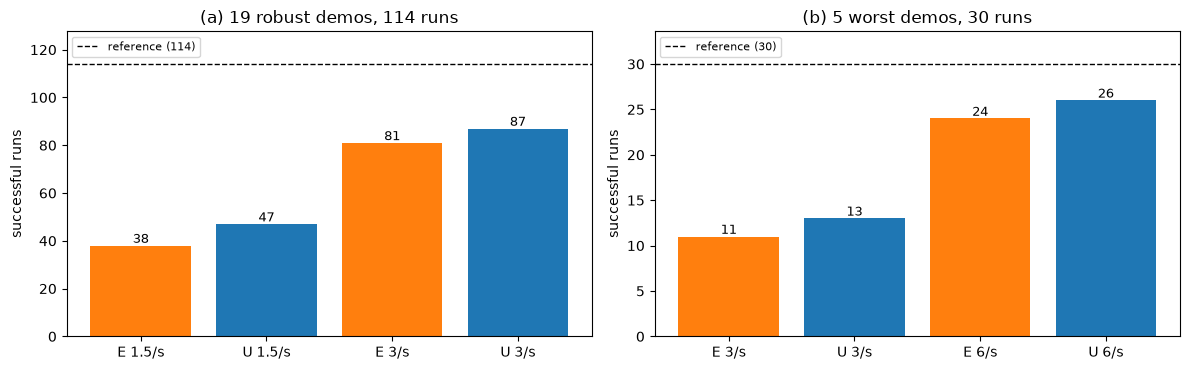

In [7]:
def bars(ax, labels, values, total, colors, title):
    ax.bar(labels, values, color=colors)
    ax.axhline(total, color="k", ls="--", lw=1, label=f"reference ({total})")
    for i, v in enumerate(values):
        ax.text(i, v + total * 0.01, str(v), ha="center", fontsize=9)
    ax.set(ylabel="successful runs", title=title, ylim=(0, total * 1.12))
    ax.legend(loc="upper left", fontsize=8)


fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(12, 3.8))
bars(ax_a, ["E 1.5/s", "U 1.5/s", "E 3/s", "U 3/s"],
     [successes(runs[n]) for n in ["h25_4_event_rho1.5", "h25_4_uniform_rho1.5", "h25_4_event_rho3", "h25_4_uniform_rho3"]],
     successes(runs["h25_4_reference"]), ["C1", "C0", "C1", "C0"], "(a) 19 robust demos, 114 runs")
bars(ax_b, ["E 3/s", "U 3/s", "E 6/s", "U 6/s"],
     [successes(runs[n], WORST) for n in ["h25_4_event_rho3", "h25_4_uniform_rho3", "h25_4_event_rho6", "h25_4_uniform_rho6"]],
     successes(runs["h25_4_reference"], WORST), ["C1", "C0", "C1", "C0"], "(b) 5 worst demos, 30 runs")
fig.tight_layout()

**Reading.** Success rises with density: from 1.5 to 3 /s on the 19 demos, and from 3 to 6 /s on the 5 worst. At 6 /s the fits get close to the reference but do not reach it. Knots at the gripper events give no benefit over uniform knots at the same K (no paired E vs U test reaches p < 0.05). So density matters, and event knots do not.

---
# Part 4. The speed rule: the chosen knot placement (H25.6)

6 /s doubles K. The question of H25.6: at the K of 3 /s, can the knot placement get the gain of 6 /s?

**Speed rule.** Weight w(t) = 1 / (v(t) + v₀), with v the commanded grip-site speed smoothed over 5 steps and v₀ = 2 cm/s. Each segment covers the same amount of ∫w dt, with a floor h_min = 0.15 s. So slow, precise motion gets short segments. (A second rule, which adds weight only in the 2 s before each release, is shown for comparison.)

The figure shows demo_16: the speed, and the segment durations of the speed rule and of uniform 3 /s at the same K.

In [8]:
demo = "demo_16"
with h5py.File(TOOL_HANG / "low_dim_abs_q0start.hdf5", "r") as f:
    th_cmd = f[f"data/{demo}/actions"][:]
with h5py.File(TOOL_HANG / "bezier_speed_rho3.hdf5", "r") as f:
    attrs = f[f"data/{demo}/bezier"].attrs
    h_speed, events = np.asarray(attrs["h"]), np.asarray(attrs["events"])
with h5py.File(TOOL_HANG / "bezier_uniform_rho3.hdf5", "r") as f:
    attrs = f[f"data/{demo}/bezier"].attrs
    h_uniform = np.full(int(attrs["ks"].sum()), attrs["durations"].sum() / attrs["ks"].sum())

th_t = CONTROL_DT * np.arange(len(th_cmd))
speed = 1.0 / speed_weight(th_cmd) - 0.02  # smoothed commanded speed, m/s
print(f"{demo}: {th_t[-1]:.2f} s, K = {len(h_speed)} (speed) and {len(h_uniform)} (uniform)")
print(f"speed rule h_k: min {h_speed.min():.3f} s, median {np.median(h_speed):.3f} s, max {h_speed.max():.3f} s; uniform h = {h_uniform[0]:.3f} s")

demo_16: 33.75 s, K = 101 (speed) and 101 (uniform)
speed rule h_k: min 0.150 s, median 0.299 s, max 0.918 s; uniform h = 0.334 s


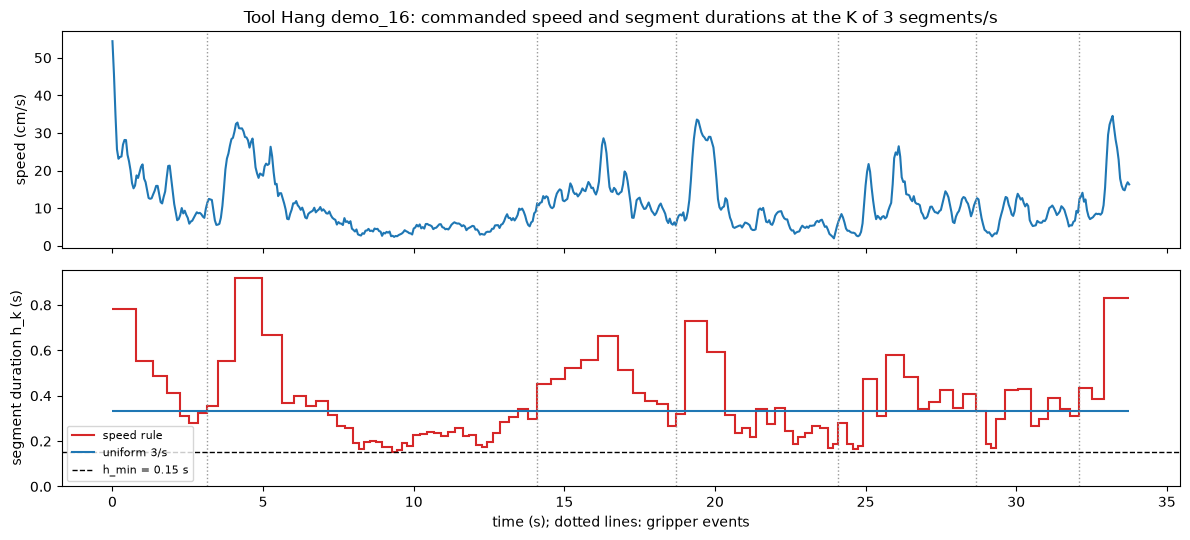

In [9]:
fig, (ax_v, ax_h) = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
ax_v.plot(th_t, 100 * speed, color="C0")
ax_v.set(ylabel="speed (cm/s)", title=f"Tool Hang {demo}: commanded speed and segment durations at the K of 3 segments/s")
for ax in (ax_v, ax_h):
    for e in events:
        ax.axvline(CONTROL_DT * e, color="0.6", ls=":", lw=1)
for h, color, label in [(h_speed, "C3", "speed rule"), (h_uniform, "C0", "uniform 3/s")]:
    tau = np.concatenate([[0.0], np.cumsum(h)])
    ax_h.stairs(h, tau, baseline=None, color=color, lw=1.5, label=label)
ax_h.axhline(0.15, color="k", ls="--", lw=1, label="h_min = 0.15 s")
ax_h.set(xlabel="time (s); dotted lines: gripper events", ylabel="segment duration h_k (s)", ylim=(0, None))
ax_h.legend(fontsize=8)
fig.tight_layout()

In [10]:
def outcome(rr):
    return {(r["demo"], r["seed"]): r["success_with_hold"] for r in rr if r["demo"] in WORST}


speed_runs, uniform_runs = outcome(runs["h25_6_speed_rho3"]), outcome(runs["h25_4_uniform_rho3"])
better = sum(speed_runs[k] and not uniform_runs[k] for k in speed_runs)
worse = sum(uniform_runs[k] and not speed_runs[k] for k in speed_runs)
p = binomtest(better, better + worse, alternative="greater").pvalue
print(f"speed rule vs uniform 3/s on the same 30 runs: better in {better}, worse in {worse}, one-sided sign test p = {p:.3f}")

speed rule vs uniform 3/s on the same 30 runs: better in 11, worse in 3, one-sided sign test p = 0.029


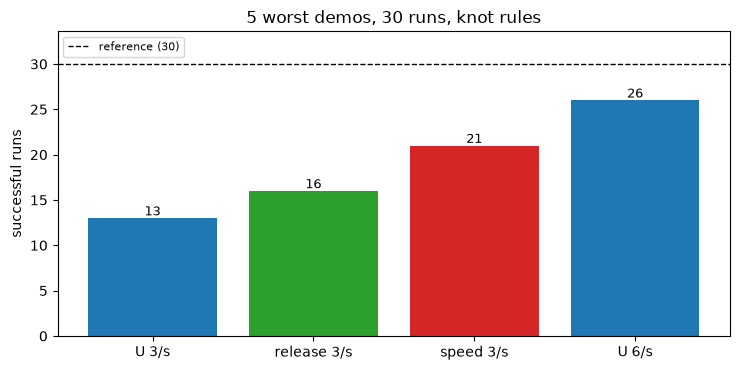

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
bars(ax, ["U 3/s", "release 3/s", "speed 3/s", "U 6/s"],
     [successes(runs[n], WORST) for n in ["h25_4_uniform_rho3", "h25_6_release_rho3", "h25_6_speed_rho3", "h25_4_uniform_rho6"]],
     successes(runs["h25_4_reference"], WORST), ["C0", "C2", "C3", "C0"], "5 worst demos, 30 runs, knot rules")
fig.tight_layout()

**Reading.** The speed rule puts short segments where the motion is slow (for example 7–13 s in demo_16) and long segments where it is fast. At the K of 3 /s it gets 21 of 30 runs, against 13 for uniform 3 /s and 26 for uniform 6 /s. The release rule gets 16: segments over the whole slow carry phases help more than segments near the release only. Similar parts of different demos get similar h_k (H25.6.2: 90/10 spread 1.73), so the durations are learnable.

**Decision (2026-11-15).** The speed rule is the knot placement for training. It does not reach the reference, but open-loop replay is fragile even for the raw commands (Part 2), and closed-loop policy success is the real measure. More density stays an option.

---
# Part 5. The training plan

Details, decisions and open questions: `docs/plan.md` (sections 3–7).

**Trajectory.** A cubic manifold Bézier spline on M = R³ × SO(3) with per-segment durations h_k. The stored controls are knots q_k and forward handles H_k. The back handle follows from H_{k+1} with the ratio ρ = h_k / h_{k+1}, so the curve is C¹ in seconds at every knot for any durations.

**Generative state.** X = (C, z, ℓ, g): the 2K + 2 control poses C, the log total duration z = log(T / 1 s), the segment logits ℓ with h_k = T · softmax(ℓ)_k, and a dense Euclidean gripper channel g. One intrinsic RFM network predicts a tangent velocity for each control pose and a Euclidean velocity for z, ℓ and g. The RFM core is ported from the S² work (H12/H13); the transformer denoiser and the R³ × SO(3) state are new.

**Two calls, one model (inpainting masks).**

| Entry | Long call | Short call |
| --- | --- | --- |
| q_0 | Known: current pose | Known: committed boundary pose |
| q_K | Generated: goal | Known: waypoint from the long plan |
| z | Generated | Known: log(Δ / 1 s) |
| ℓ | Generated | Known: ℓ = 0 (equal segments) |
| H_0 | Generated | Known: from the inherited start velocity |
| Other controls, H_K, g | Generated | Generated |

**Execution.** Receding: while the robot executes one interval of length Δ, the short call generates the next one and the long call refreshes the plan. Start with the short call alone, then add the long call.

**Protocol.** As DP and LieSpline-DP: all 200 PH demos, 50 env seeds every 50 epochs, 3 training seeds, Best and Last-10. DP-T runs in the same pipeline as the baseline. Targets: DP-T 1.00 / 0.87, LieSpline-DP 93.33 / 81.27.

**Open before the dataset (plan.md section 7).** (1) K for the two calls, (2) which intervals are long-call targets, (3) fixed K vs density, (4) the length of the gripper channel.